# Exploración del dataset (Fase 5)

Distribuciones de las competencias, cobertura de las features y su relación con el resultado.
Se regenera con `python -m features.build_dataset` y luego *Run All*.

- **pct**: posición / n_equipos (0 = primero). **pct_bo**: lo mismo, pero solo entre los equipos bolivianos de la competencia (target del MVP). Empates promediados.
- Todas las features están calculadas "a la fecha" (solo con competencias anteriores).

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

df = pd.read_parquet(RAIZ / "data" / "dataset.parquet")
bo = df[df["pais"] == "BO"].copy()
conn = sqlite3.connect(RAIZ / "data" / "db.sqlite")
print(f"{len(df)} equipos-competencia, {len(bo)} bolivianos, {df['slug'].nunique()} competencias")

4052 equipos-competencia, 1287 bolivianos, 13 competencias


## 1. Tamaño de las competencias

,slug,tipo,fecha,equipos,bolivianos,% bolivianos
0,latam-2019,regional,2019-11-07,343,26,7.6
1,latam-2020,regional,2021-07-08,302,14,4.6
2,latam-2021,regional,2022-04-01,252,22,8.7
8,subbr-2022,nacional,2022-10-08,100,100,100.0
3,latam-2022,regional,2023-03-16,309,51,16.5
9,subbr-2023,nacional,2023-09-01,153,153,100.0
4,latam-2023,regional,2023-10-19,404,73,18.1
10,subbr-2024,nacional,2024-08-30,189,189,100.0
5,latam-2024,regional,2024-11-07,490,79,16.1
11,subbr-2025,nacional,2025-09-12,197,197,100.0


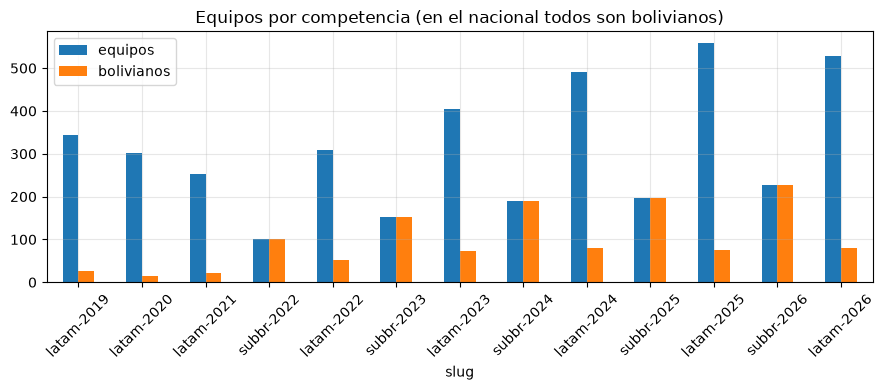

In [2]:
tam = (
    df.groupby(["slug", "tipo", "fecha"])
    .agg(equipos=("equipo_id", "size"), bolivianos=("pais", lambda s: (s == "BO").sum()))
    .reset_index()
    .sort_values("fecha")
)
tam["% bolivianos"] = (100 * tam["bolivianos"] / tam["equipos"]).round(1)
display(tam)
ax = tam.set_index("slug")[["equipos", "bolivianos"]].plot.bar(rot=45)
ax.set_title("Equipos por competencia (en el nacional todos son bolivianos)")
plt.tight_layout()

## 2. Problemas resueltos por los equipos bolivianos

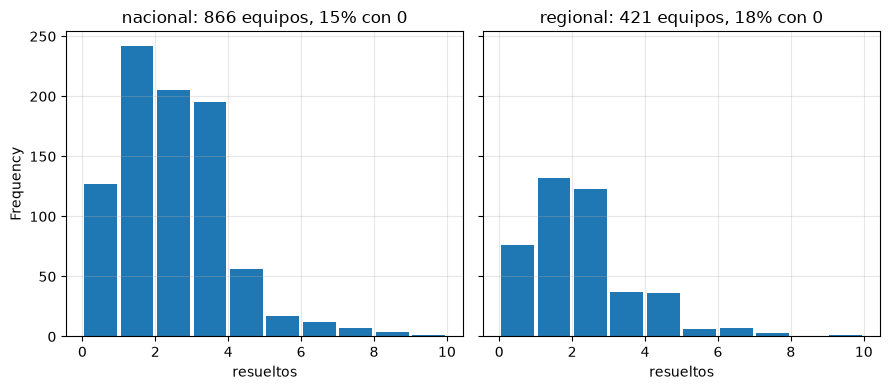

In [3]:
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, tipo in zip(axes, ["nacional", "regional"], strict=True):
    sub = bo[bo["tipo"] == tipo]
    sub["resueltos"].plot.hist(bins=range(0, int(sub["resueltos"].max()) + 2), ax=ax, rwidth=0.9)
    ax.set_title(f"{tipo}: {len(sub)} equipos, {100 * (sub['resueltos'] == 0).mean():.0f}% con 0")
    ax.set_xlabel("resueltos")
plt.tight_layout()

Muchos equipos con 0 o 1 resueltos: por eso los empates se promedian en el target (si no, el orden entre ellos sería ruido).

## 3. Cobertura de las features (equipos bolivianos)

In [4]:
from models.modelos import FEATURES

feats = [f for f in FEATURES if f in bo.columns]
cobertura = (bo[feats].notna().groupby(bo["tipo"]).mean().T * 100).round(0)
cobertura.columns.name = "% con dato"
display(cobertura.sort_values("nacional"))

% con dato,nacional,regional
eq_pct_previo,12.0,74.0
uni_cf_max_rating,56.0,67.0
uni_cf_top3_rating,56.0,67.0
uni_mejor_pct_3a_nacional,82.0,75.0
uni_mejor_pct_3a_regional,82.0,76.0
uni_mejor_pct_ultima_nacional,82.0,75.0
uni_mejor_pct_ultima_regional,82.0,76.0
uni_media_pct_3a_nacional,82.0,75.0
uni_media_pct_3a_regional,82.0,76.0
uni_comps_previas_regional,98.0,87.0


## 4. Correlación de cada feature con el resultado

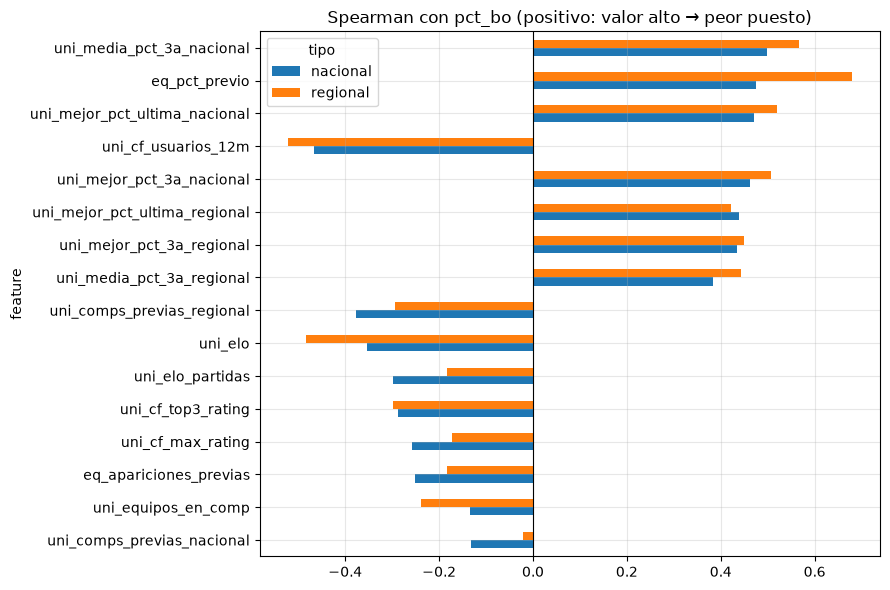

In [5]:
filas = []
for f in feats:
    for tipo in ["nacional", "regional"]:
        sub = bo[(bo["tipo"] == tipo) & bo[f].notna()]
        if len(sub) > 20:
            rho = sub[f].astype(float).corr(sub["pct_bo"], method="spearman")
            filas.append({"feature": f, "tipo": tipo, "spearman": rho, "n": len(sub)})
corr = pd.DataFrame(filas).pivot(index="feature", columns="tipo", values="spearman")
corr = corr.reindex(corr["nacional"].abs().sort_values().index)
ax = corr.plot.barh(figsize=(9, 6))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Spearman con pct_bo (positivo: valor alto → peor puesto)")
plt.tight_layout()

Las de percentil previo (de la universidad o del equipo) correlacionan positivo: un historial peor anticipa un puesto peor. Las de rating CF y número de usuarios activos correlacionan negativo: más talento en CF → mejor puesto.

## 5. El resultado previo del mismo equipo

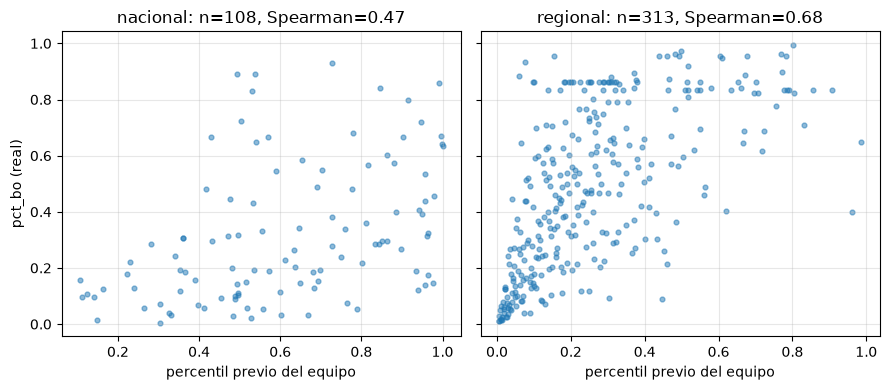

In [6]:
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, tipo in zip(axes, ["nacional", "regional"], strict=True):
    sub = bo[(bo["tipo"] == tipo) & bo["eq_pct_previo"].notna()]
    ax.scatter(sub["eq_pct_previo"], sub["pct_bo"], s=12, alpha=0.5)
    rho = sub["eq_pct_previo"].corr(sub["pct_bo"], method="spearman")
    ax.set_title(f"{tipo}: n={len(sub)}, Spearman={rho:.2f}")
    ax.set_xlabel("percentil previo del equipo")
axes[0].set_ylabel("pct_bo (real)")
plt.tight_layout()

## 6. Universidades bolivianas en el nacional

In [7]:
nac = bo[bo["tipo"] == "nacional"]
unis = (
    nac.groupby("uni")
    .agg(
        equipos=("equipo_id", "size"),
        pct_medio=("pct_bo", "mean"),
        mejor=("pct_bo", "min"),
        nacionales=("slug", "nunique"),
    )
    .query("equipos >= 10")
    .sort_values("pct_medio")
)
display(unis.round(3))

,equipos,pct_medio,mejor,nacionales
uni,,,,
UMSA,30,0.141,0.004,5
UMSS,55,0.236,0.005,5
UPB,41,0.260,0.032,5
USB,12,0.339,0.030,4
UCB,100,0.380,0.009,5
UTO,54,0.421,0.026,5
EMI,52,0.477,0.075,5
UTEPSA,13,0.485,0.117,5
UAJMS,58,0.492,0.053,5


Las universidades grandes inscriben muchos equipos: su **mejor** equipo suele estar arriba, pero su percentil **medio** no tanto. Eso explica el signo contraintuitivo de "nacionales jugados por la universidad" en el Ridge.

## 7. Codeforces en Bolivia

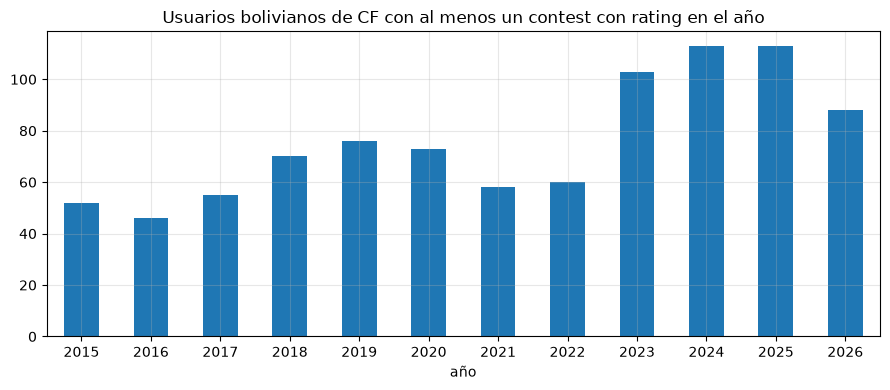

In [8]:
hist = pd.read_sql_query("SELECT handle, fecha, rating FROM historial_rating", conn)
hist["año"] = hist["fecha"].str[:4].astype(int)
activos = hist[hist["año"] >= 2015].groupby("año")["handle"].nunique()
ax = activos.plot.bar(rot=0)
ax.set_title("Usuarios bolivianos de CF con al menos un contest con rating en el año")
plt.tight_layout()

In [9]:
from features.universidad_cf import cargar_historial_por_universidad

h = cargar_historial_por_universidad(conn)
ultimo = h.sort_values("fecha").groupby("handle").tail(1)
display(
    ultimo.groupby("uni")["rating"]
    .agg(["size", "max", "median"])
    .sort_values("size", ascending=False)
    .rename(columns={"size": "usuarios"})
)

,usuarios,max,median
uni,,,
UMSA,41,1673,1100.0
UMSS,41,1947,1188.0
UCB,18,1457,1195.5
UPB,15,1547,994.0
UTO,9,1679,1066.0
UPDS,7,1447,1297.0
UAGRM,7,1377,1109.0
UPSA,7,1916,1371.0
UAJMS,4,2025,1296.5


## Conclusiones

- Solo una minoría de los competidores bolivianos tiene rating en Codeforces: el cold start es la norma.
- Sin integrantes, la mejor señal es el resultado previo del mismo equipo (cuando existe) y el historial y talento CF de su universidad.
- El nacional se predice peor que la regional: a la regional llegan equipos con historial; en el nacional ~2/3 no tienen historial propio.
- Lo que más mejoraría el modelo: identificar integrantes (aunque sea solo de los equipos fuertes) para usar su rating a la fecha.